# Delineo Use Cases — School Infection Hotspots (Barnsdall, OK) · Week 7

**Feedback from Week 6:** use longer intervention times.

What changed in this notebook:

1. **Interventions spread across the whole run.** Last week every start was in the first week (hours 12 / 72 / 168). Start times now span the run: days 0.5, 3, 7, 14 and 21, with a no-intervention baseline. The site caps runs at 720 h (30 days, the April 2021 mobility data), so `SIM_HOURS = 720`.
2. **Window limit is tracked.** In Week 5/6 every run that spread peaked in the last 20 hours of the window. The truncation check reports this for every new run, so results are read as "outbreak size by day 30", not final size.
3. **Repeats.** Each scenario is run `REPEATS` times because the simulator uses a random seed and a random initial infected person.
4. **Settings audit runs before any analysis.** In Week 5/6, 9 of 10 runs had stored intervention schedules that did not match what we registered. Runs that fail the audit are now excluded by default (`EXCLUDE_FAILED_AUDIT`).
5. **New outputs:** epidemic curves with the intervention start marked, a truncation check ("is the outbreak still growing at the end?"), per-scenario summaries across repeats, and an hourly school section that works for any window length.

**How to use it:** submit the runs listed by the *run sheet* cell on the Delineo site, paste their run IDs into `RUN_IDS`, then *Run All*. To re-check the pipeline on last week's runs (187–196), set `ANALYSIS = "week6"`.

In [15]:
# import required packages
import requests
import pandas as pd
import numpy as np
import json
import time as _time
import warnings
from pathlib import Path
from urllib.parse import urlencode
from numbers import Integral, Real
from concurrent.futures import ThreadPoolExecutor, as_completed
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

BASE_URL = "https://covidmod.isi.jhu.edu/api"
SITE_URL = "https://covidmod.isi.jhu.edu"
EXPORT_DIR = Path("delineo_exports")
SESSION = requests.Session()

## 1. Experiment design

One intervention family (50% vaccination, continuing last week's timing comparison) at five start times plus a baseline. Every intervention stays on until the end of the run. All other settings — zone, population, mobility, disease model, one initial infection — stay fixed.

Fill `RUN_IDS` as you submit runs. Leave `None` for runs not yet submitted; the notebook analyzes whatever is filled in.

In [16]:
def policy(hour, masking=0, vaccinated=0, lockdown=0, self_isolation=0):
    return dict(hour=hour, masking=masking, vaccinated=vaccinated,
                lockdown=lockdown, self_isolation=self_isolation)

ANALYSIS = "week7"        # "week7" = new runs; "week6" = re-check last week's runs 187–196

# ---- Week 7 design ---------------------------------------------------------------
SIM_HOURS = 720           # 30 days — the site's maximum (April 2021 mobility data)
REPEATS = 3
INTERVENTION = dict(vaccinated=50)          # change to e.g. dict(masking=40) to test another measure
START_HOURS = [12, 72, 168, 336, 504]       # day 0.5, 3, 7, 14, 21

SCENARIOS = [{"label": "B0", "interventions": []}] + [
    {"label": f"V50-D{h/24:g}", "interventions": [policy(h, **INTERVENTION)]}
    for h in START_HOURS
]

# Paste run IDs here as you submit them: one list per scenario, one ID per repeat.
RUN_IDS = {
    "B0":       [None, None, None],
    "V50-D0.5": [None, None, None],
    "V50-D3":   [None, None, None],
    "V50-D7":   [217, None, None],
    "V50-D14":  [None, None, None],
    "V50-D21":  [None, None, None],
}

# ---- Week 5/6 runs (720 h), kept for re-checking the pipeline -------------------
WEEK6_RUNS = [
    {"run_id": 187, "scenario": "B0",        "interventions": []},
    {"run_id": 188, "scenario": "M50-H12",   "interventions": [policy(12, masking=50)]},
    {"run_id": 189, "scenario": "V50-H12",   "interventions": [policy(12, vaccinated=50)]},
    {"run_id": 190, "scenario": "L50-H12",   "interventions": [policy(12, lockdown=50)]},
    {"run_id": 191, "scenario": "I50-H12",   "interventions": [policy(12, self_isolation=50)]},
    {"run_id": 192, "scenario": "MV50-H12",  "interventions": [policy(12, masking=50, vaccinated=50)]},
    {"run_id": 193, "scenario": "LI50-H12",  "interventions": [policy(12, lockdown=50, self_isolation=50)]},
    {"run_id": 194, "scenario": "ALL50-H12", "interventions": [policy(12, masking=50, vaccinated=50, lockdown=50, self_isolation=50)]},
    {"run_id": 195, "scenario": "V50-H72",   "interventions": [policy(72, vaccinated=50)]},
    {"run_id": 196, "scenario": "V50-H168",  "interventions": [policy(168, vaccinated=50)]},
]

def build_runs():
    if ANALYSIS == "week6":
        return 720, [dict(r, initial=policy(0), replicate=1, label=f"{r['scenario']}-r1") for r in WEEK6_RUNS]
    if ANALYSIS != "week7":
        raise ValueError('ANALYSIS must be "week7" or "week6"')
    unknown = set(RUN_IDS) - {s["label"] for s in SCENARIOS}
    if unknown:
        raise ValueError(f"RUN_IDS has labels not in SCENARIOS: {sorted(unknown)}")
    runs = []
    for s in SCENARIOS:
        ids = list(RUN_IDS.get(s["label"], []))
        ids += [None] * (REPEATS - len(ids))
        for k, rid in enumerate(ids, start=1):
            runs.append({"run_id": rid, "scenario": s["label"], "replicate": k,
                         "label": f"{s['label']}-r{k}", "initial": policy(0),
                         "interventions": s["interventions"]})
    return SIM_HOURS, runs

WINDOW_HOURS, RUNS = build_runs()
BASELINE_SCENARIO = "B0"
SCENARIO_ORDER = list(dict.fromkeys(r["scenario"] for r in RUNS))
print(f"Analysis: {ANALYSIS} | window: {WINDOW_HOURS} h ({WINDOW_HOURS/24:g} days) | runs defined: {len(RUNS)}")

Analysis: week7 | window: 720 h (30 days) | runs defined: 18


In [17]:
PERCENT_FIELDS = ("masking", "vaccinated", "lockdown", "self_isolation")

def checked_integer(value, name, minimum=0):
    if isinstance(value, bool) or not isinstance(value, Integral) or value < minimum:
        raise ValueError(f"{name} must be an integer >= {minimum}; received {value!r}")
    return int(value)

def validate_policy(p, initial=False):
    h = checked_integer(p["hour"], "hour", 0 if initial else 1)
    if initial and h != 0:
        raise ValueError("The initial policy hour must be 0")
    if h >= WINDOW_HOURS:
        raise ValueError(f"Intervention hour {h} is not inside the {WINDOW_HOURS} h window")
    for key in PERCENT_FIELDS:
        v = p[key]
        if isinstance(v, bool) or not isinstance(v, Real) or not 0 <= v <= 100:
            raise ValueError(f"{key} must be between 0 and 100")

def validate_runs(runs):
    seen = set()
    for run in runs:
        validate_policy(run["initial"], initial=True)
        hours = []
        for p in run["interventions"]:
            validate_policy(p)
            hours.append(p["hour"])
        if hours != sorted(set(hours)):
            raise ValueError(f"{run['label']}: intervention times must be strictly increasing and unique")
        if run["run_id"] is None:
            continue
        rid = checked_integer(run["run_id"], "run_id", 1)
        if rid in seen:
            raise ValueError(f"Duplicate run_id: {rid}")
        seen.add(rid)

def run_urls(run_id):
    rid = checked_integer(run_id, "run_id", 1)
    return {"result_url": f"{SITE_URL}/simulator/{rid}",
            "chart_url": f"{BASE_URL}/simdata/{rid}/chartdata",
            "map_url": f"{BASE_URL}/simdata/{rid}/map"}

def snapshot_url(run_id, api_time):
    # api_time is an API timestamp from map_data['timesteps'] (minutes), not an intervention hour.
    return run_urls(run_id)["map_url"] + "?" + urlencode({"time": checked_integer(api_time, "API time")})

def fetch_json(url, timeout=120, retries=3):
    for attempt in range(retries):
        try:
            response = SESSION.get(url, timeout=timeout)
            response.raise_for_status()
            payload = response.json()
            break
        except (requests.ConnectionError, requests.Timeout):
            if attempt == retries - 1:
                raise
            _time.sleep(2 ** attempt)
    if not isinstance(payload, dict) or "data" not in payload:
        raise ValueError(f"Response is missing the data field: {url}")
    return payload

def load_run(run_id):
    urls = run_urls(run_id)
    return {"run_id": run_id, "urls": urls,
            "chart_json": fetch_json(urls["chart_url"]),
            "map_json": fetch_json(urls["map_url"])}

def get_snapshot(run_id, api_time):
    return fetch_json(snapshot_url(run_id, api_time))["data"]

def intervention_text(interventions):
    if not interventions:
        return "none"
    return "; ".join(f"from hour {p['hour']} (day {p['hour']/24:g}): " +
                     ", ".join(f"{k} {p[k]}%" for k in PERCENT_FIELDS if p[k]) for p in interventions)

## 2. Run sheet

This is the list of simulations to submit on the Delineo site. It is saved to `delineo_exports/run_sheet.csv`.

**Entering a run on the site:**
1. Simulation Length: 720 hours (slider all the way right). Random Seed: checked. Initial Infected: 1.
2. Baseline (B0) runs: add no intervention — just click **Simulate**.
3. Intervention runs: drag the black handle on the Interventions timeline until the heading reads the start hour (e.g. **Hour 168**), set **Percent Vaccinated** to 50%, then click **+ Add Intervention**.
4. Before simulating, check that a row with that hour and Vaccine 50% appears next to the SEED row. The panel starts at Hour 001 and nothing is saved until you click **+ Add Intervention** — the likely cause of last week's mismatched runs.
5. Click **Simulate**; the run ID is the number at the end of the results URL (`/simulator/<id>`).

In [18]:
validate_runs(RUNS)
run_sheet = pd.DataFrame([{
    "label": r["label"], "scenario": r["scenario"], "replicate": r["replicate"],
    "simulation_hours": WINDOW_HOURS, "simulation_days": WINDOW_HOURS / 24,
    "interventions": intervention_text(r["interventions"]),
    "run_id": r["run_id"],
} for r in RUNS])
run_sheet["run_id"] = run_sheet["run_id"].astype("Int64")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)
run_sheet.to_csv(EXPORT_DIR / "run_sheet.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(run_sheet)

active_runs = [r for r in RUNS if r["run_id"] is not None]
pending = [r["label"] for r in RUNS if r["run_id"] is None]
print(f"Runs with IDs: {len(active_runs)} | awaiting IDs: {len(pending)}")
if pending:
    print("  awaiting:", ", ".join(pending))
if not active_runs:
    raise SystemExit("No run IDs yet. Submit the runs above, paste their IDs into RUN_IDS, then Run All.")
(EXPORT_DIR / "run_registry.json").write_text(json.dumps(RUNS, indent=2), encoding="utf-8")

,label,scenario,replicate,simulation_hours,simulation_days,interventions,run_id
0,B0-r1,B0,1,720,30.0,none,<NA>
1,B0-r2,B0,2,720,30.0,none,<NA>
2,B0-r3,B0,3,720,30.0,none,<NA>
3,V50-D0.5-r1,V50-D0.5,1,720,30.0,from hour 12 (day 0.5): vaccinated 50%,<NA>
4,V50-D0.5-r2,V50-D0.5,2,720,30.0,from hour 12 (day 0.5): vaccinated 50%,<NA>
5,V50-D0.5-r3,V50-D0.5,3,720,30.0,from hour 12 (day 0.5): vaccinated 50%,<NA>
6,V50-D3-r1,V50-D3,1,720,30.0,from hour 72 (day 3): vaccinated 50%,<NA>
7,V50-D3-r2,V50-D3,2,720,30.0,from hour 72 (day 3): vaccinated 50%,<NA>
8,V50-D3-r3,V50-D3,3,720,30.0,from hour 72 (day 3): vaccinated 50%,<NA>
9,V50-D7-r1,V50-D7,1,720,30.0,from hour 168 (day 7): vaccinated 50%,217


Runs with IDs: 1 | awaiting IDs: 17
  awaiting: B0-r1, B0-r2, B0-r3, V50-D0.5-r1, V50-D0.5-r2, V50-D0.5-r3, V50-D3-r1, V50-D3-r2, V50-D3-r3, V50-D7-r2, V50-D7-r3, V50-D14-r1, V50-D14-r2, V50-D14-r3, V50-D21-r1, V50-D21-r2, V50-D21-r3


6718

## 3. Load runs (cached)

In [19]:
REFRESH_CACHE = False
CACHE_DIR = EXPORT_DIR / "raw"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
loaded_runs = {}
for run in active_runs:
    rid = run["run_id"]
    path = CACHE_DIR / f"run_{rid}.json"
    if path.exists() and not REFRESH_CACHE:
        data = json.loads(path.read_text(encoding="utf-8"))
        if data.get("run_id") != rid:
            raise ValueError(f"Cache ID mismatch: {path}")
    else:
        data = load_run(rid)
        path.write_text(json.dumps(data), encoding="utf-8")
    data["label"], data["scenario"], data["params"] = run["label"], run["scenario"], run
    loaded_runs[rid] = data
    print(f"Loaded {run['label']} / run {rid}")

rows = []
for rid, entry in loaded_runs.items():
    m = entry["map_json"]["data"]
    ts = m["timesteps"]
    if not ts:
        raise ValueError(f"run {rid} has no timesteps")
    rows.append(dict(label=entry["label"], scenario=entry["scenario"], run_id=rid,
                     n_homes=len(m["papdata"]["homes"]), n_places=len(m["papdata"]["places"]),
                     n_timesteps=len(ts), last_api_time=max(ts), window_hours=max(ts) / 60))
overview = pd.DataFrame(rows)
display(overview)
overview.to_csv(EXPORT_DIR / "run_overview.csv", index=False, encoding="utf-8-sig")

# Window check: make sure every run used the planned length.
short = overview[overview["window_hours"] < WINDOW_HOURS]
if not short.empty:
    warnings.warn(f"{len(short)} run(s) are shorter than the planned {WINDOW_HOURS} h window: "
                  f"{short['run_id'].tolist()} — check the simulation length on the site.")
if overview["window_hours"].nunique() != 1:
    raise ValueError("Runs have different window lengths; results would not be comparable")
API_MIN_PER_HOUR = 60   # API timestamps are minutes (43200 = 720 h)

Loaded V50-D7-r1 / run 217


,label,scenario,run_id,n_homes,n_places,n_timesteps,last_api_time,window_hours
0,V50-D7-r1,V50-D7,217,21433,3180,720,43200,720.0


## 4. Settings audit (before any analysis)

Compares the schedule we registered with the schedule stored in each run's metadata. The site's metadata `time` unit is not documented, so a match in hours, minutes or days is accepted and the matching unit is reported. In Week 5/6, metadata for runs 188–196 did **not** match: 188 and 189 both stored *masking 50% from time 1*, and 190–196 stored no intervention at all.

In [20]:
EXCLUDE_FAILED_AUDIT = True   # set False only to look at unverified runs; label any such result "unverified"
AUDIT_DIR = EXPORT_DIR / "audit"; AUDIT_DIR.mkdir(parents=True, exist_ok=True)
UNIT_DIVISORS = {"hours": 1, "minutes": 60, "days": 1 / 24}

def registered_schedule(run):
    return sorted((float(p["hour"]), *(round(p[k] / 100, 8) for k in PERCENT_FIELDS))
                  for p in [run["initial"]] + run["interventions"])

def metadata_schedule(md_interventions, divisor):
    if md_interventions is None:
        return None
    return sorted((float(row["time"]) / divisor,
                   *(round(float(row[k]), 8) for k in ("mask", "vaccine", "lockdown", "selfiso")))
                  for row in md_interventions)

def schedule_text(s):
    if s is None:
        return "missing"
    return "; ".join(f"H{h:g}: M{m*100:g}/V{v*100:g}/L{l*100:g}/I{i*100:g}" for h, m, v, l, i in s)

audit_rows = []
for rid, entry in loaded_runs.items():
    m = entry["map_json"]["data"]; md_ = m.get("metadata", {})
    expected = registered_schedule(entry["params"])
    matched = next((u for u, d in UNIT_DIVISORS.items()
                    if metadata_schedule(md_.get("interventions"), d) == expected), None)
    audit_rows.append({
        "run_id": rid, "label": entry["label"], "scenario": entry["scenario"],
        "passes": matched is not None, "matched_time_unit": matched,
        "registered": schedule_text(expected),
        "stored_raw": json.dumps(md_.get("interventions")),
        "random_seed_behavior": md_.get("random_seed_behavior"),
        "initial_infected_count": md_.get("initial_infected_count"),
        "initial_infected_ids": json.dumps(md_.get("initial_infected_ids")),
        "zone_id": m["zone"].get("id"), "papdata_id": m["zone"].get("papdata_id"),
        "patterns_id": m["zone"].get("patterns_id"),
    })
parameter_audit = pd.DataFrame(audit_rows)
with pd.option_context("display.max_colwidth", 80):
    display(parameter_audit[["run_id", "label", "passes", "matched_time_unit", "registered", "stored_raw",
                             "initial_infected_count"]])
parameter_audit.to_csv(AUDIT_DIR / "parameter_audit.csv", index=False, encoding="utf-8-sig")
for col in ("zone_id", "papdata_id", "patterns_id"):
    if parameter_audit[col].isna().any() or parameter_audit[col].nunique() != 1:
        raise ValueError(f"{col} differs or is missing; runs must share zone, population and mobility data")
if parameter_audit["initial_infected_count"].nunique() > 1:
    warnings.warn("Runs start with different numbers of initial infections")

failed = parameter_audit.loc[~parameter_audit["passes"], "run_id"].tolist()
print(f"Audit: {parameter_audit['passes'].sum()} of {len(parameter_audit)} runs match the registered schedule.")
if failed:
    msg = f"Runs whose stored schedule does not match: {failed}."
    if EXCLUDE_FAILED_AUDIT:
        for rid in failed:
            loaded_runs.pop(rid)
        msg += " They are EXCLUDED from the analysis below (EXCLUDE_FAILED_AUDIT=True)."
    else:
        msg += " They are INCLUDED; treat their results as unverified outcomes, not intervention effects."
    warnings.warn(msg)
if not loaded_runs:
    raise SystemExit("No runs passed the audit. Check how interventions are entered on the site "
                     "(see stored_raw) before re-running; nothing below would be interpretable.")
run_order = list(loaded_runs)
scenario_of = {rid: e["scenario"] for rid, e in loaded_runs.items()}
SCENARIO_ORDER = [s for s in SCENARIO_ORDER if s in set(scenario_of.values())]
start_hour_of = {s["label"] if "label" in s else s["scenario"]:
                 (s["interventions"][0]["hour"] if s["interventions"] else None)
                 for s in (SCENARIOS if ANALYSIS == "week7" else WEEK6_RUNS)}
print("Runs analyzed:", run_order)

,run_id,label,passes,matched_time_unit,registered,stored_raw,initial_infected_count
0,217,V50-D7-r1,True,hours,H0: M0/V0/L0/I0; H168: M0/V50/L0/I0,"[{""mask"": 0, ""time"": 0, ""selfiso"": 0, ""vaccine"": 0, ""capacity"": 1, ""lockdown...",1


Audit: 1 of 1 runs match the registered schedule.
Runs analyzed: [217]


## 5. Epidemic curves

,min,max,count
label,,,
V50-D7-r1,1,720,720


,run_id,scenario,label,attributed_infections,peak_Infected,peak_day,end_Infected,peak_in_last_5pct,still_active_at_end
0,217,V50-D7,V50-D7-r1,1.0,1,0.041667,0,False,False


,start_day,n_runs,n_spread,median_infections,min_infections,max_infections,median_peak,median_peak_day,n_peak_at_end
scenario,,,,,,,,,
V50-D7,7.0,1,0,1.0,1.0,1.0,1.0,0.041667,0


0 of 0 spreading runs peak in the last 5% of the window — the window captures the peaks.


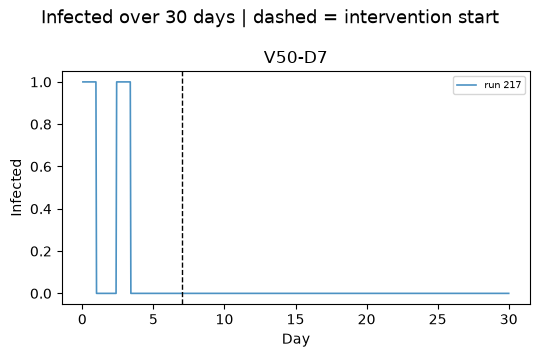

In [21]:
frames = []
for rid, entry in loaded_runs.items():
    df = pd.DataFrame(entry["chart_json"]["data"]["states"])
    if df.empty or "time" not in df:
        raise ValueError(f"{entry['label']} has no time series")
    df["time"] = pd.to_numeric(df["time"], errors="raise")
    if df["time"].isna().any() or df["time"].duplicated().any():
        raise ValueError(f"{entry['label']} contains missing or duplicate timestamps")
    df["run_id"], df["scenario"], df["label"] = rid, entry["scenario"], entry["label"]
    frames.append(df.sort_values("time"))
states_df = pd.concat(frames, ignore_index=True)
states_df["day"] = states_df["time"] / 24
states_df.to_csv(EXPORT_DIR / "all_states.csv", index=False, encoding="utf-8-sig")
display(states_df.groupby("label")["time"].agg(["min", "max", "count"]))

METRIC = "Infected"
END_FRACTION = 0.05     # a peak in the last 5% of the window means the outbreak may still be growing
rows = []
for rid, g in states_df.groupby("run_id"):
    g = g.sort_values("time")
    tmax = g["time"].max()
    peak = g.loc[g[METRIC].idxmax()]
    m = loaded_runs[rid]["map_json"]["data"]
    total = float(m["incidence"]["home"]) + float(sum(m["incidence"]["places"].values()))
    rows.append({
        "run_id": rid, "scenario": scenario_of[rid], "label": loaded_runs[rid]["label"],
        "attributed_infections": total,
        "peak_" + METRIC: peak[METRIC], "peak_day": peak["time"] / 24,
        "end_" + METRIC: g[METRIC].iloc[-1],
        "peak_in_last_5pct": peak["time"] >= (1 - END_FRACTION) * tmax,
        "still_active_at_end": g[METRIC].iloc[-1] > 0,
    })
run_summary = pd.DataFrame(rows)
display(run_summary)
run_summary.to_csv(EXPORT_DIR / "run_summary.csv", index=False, encoding="utf-8-sig")

SPREAD_THRESHOLD = 10   # runs with fewer attributed infections are treated as "did not spread"
scenario_summary = (run_summary.assign(spread=run_summary["attributed_infections"] >= SPREAD_THRESHOLD)
    .groupby("scenario")
    .agg(n_runs=("run_id", "count"), n_spread=("spread", "sum"),
         median_infections=("attributed_infections", "median"),
         min_infections=("attributed_infections", "min"),
         max_infections=("attributed_infections", "max"),
         median_peak=("peak_" + METRIC, "median"), median_peak_day=("peak_day", "median"),
         n_peak_at_end=("peak_in_last_5pct", "sum"))
    .reindex(SCENARIO_ORDER))
scenario_summary.insert(0, "start_day", [None if start_hour_of.get(s) is None else start_hour_of[s] / 24
                                         for s in scenario_summary.index])
display(scenario_summary)
scenario_summary.to_csv(EXPORT_DIR / "scenario_summary.csv", encoding="utf-8-sig")
n_trunc = int(run_summary["peak_in_last_5pct"].sum()); n_sp = int((run_summary["attributed_infections"] >= SPREAD_THRESHOLD).sum())
print(f"{n_trunc} of {n_sp} spreading runs peak in the last 5% of the window"
      + (" — read totals as infections by the end of the run, not final outbreak size." if n_trunc else " — the window captures the peaks."))

# Figure 0: epidemic curves per scenario; thin lines = repeats, dashed line = intervention start
n = len(SCENARIO_ORDER); ncols = min(3, n); nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.6 * nrows), sharex=True, sharey=True, squeeze=False)
for ax, sc in zip(axes.flat, SCENARIO_ORDER):
    for rid, g in states_df[states_df["scenario"] == sc].groupby("run_id"):
        ax.plot(g["day"], g[METRIC], lw=1.2, alpha=.8, label=f"run {rid}")
    if start_hour_of.get(sc) is not None:
        ax.axvline(start_hour_of[sc] / 24, ls="--", color="k", lw=1)
    ax.set_title(sc); ax.set_xlabel("Day"); ax.set_ylabel(METRIC); ax.legend(fontsize=7)
for ax in list(axes.flat)[n:]:
    ax.set_visible(False)
fig.suptitle(f"{METRIC} over {WINDOW_HOURS/24:g} days | dashed = intervention start", fontsize=13)
fig.tight_layout(); fig.savefig(EXPORT_DIR / "00_epidemic_curves.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

# POI infection comparisons

Counts come from `map_json.data.incidence.places` and `incidence.home` (validated last week: run 189 → 569 POI, 725 home, 137 at St John Catholic School). Do not substitute `hotspots` list lengths or `poiPeaks.infected` for attributed counts.

With repeats, scenario comparisons use the **median across repeats**; single runs are shown only to display variability. Output directory: `delineo_exports/poi_comparison/`.

In [22]:
POI_OUTPUT_DIR = EXPORT_DIR / "poi_comparison"; POI_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TOP_N = 15

def save_poi_figure(fig, name):
    fig.savefig(POI_OUTPUT_DIR / f"{name}.png", dpi=180, bbox_inches="tight")
    plt.show(); plt.close(fig)

poi_frames, transmission_rows = [], []
reference_keys = None
for rid, entry in loaded_runs.items():
    m = entry["map_json"]["data"]
    places = pd.DataFrame(m["papdata"]["places"]).copy()
    places["place_id"] = places["id"].astype(str)
    if places["place_id"].tolist() != [str(i) for i in range(len(places))]:
        raise ValueError(f"run {rid}: id differs from the array index; verify the incidence mapping again")
    if places["placekey"].isna().any() or places["placekey"].duplicated().any():
        raise ValueError(f"run {rid}: placekey is missing or duplicated")
    keys = set(places["placekey"])
    if reference_keys is None:
        reference_keys = keys
    elif keys != reference_keys:
        raise ValueError(f"run {rid}: POI sets differ; missing places must not be treated as zero infections")
    incidence = m.get("incidence")
    if not isinstance(incidence, dict) or not isinstance(incidence.get("places"), dict) or "home" not in incidence:
        raise ValueError(f"run {rid}: complete incidence summary is missing")
    counts = {str(k): v for k, v in incidence["places"].items()}
    if set(counts) - set(places["place_id"]):
        raise ValueError(f"run {rid}: incidence contains unmatched POIs")
    places["infections"] = pd.to_numeric(places["place_id"].map(counts).fillna(0), errors="raise")
    home = float(incidence["home"])
    values = np.r_[places["infections"].to_numpy(), home]
    if not np.isfinite(values).all() or (values < 0).any() or (values != np.floor(values)).any():
        raise ValueError(f"run {rid}: invalid infection counts")
    places["run_id"], places["scenario"] = rid, entry["scenario"]
    places["top_category"] = places["top_category"].fillna("Unknown")
    poi_frames.append(places[["run_id", "scenario", "placekey", "place_id", "label",
                              "top_category", "latitude", "longitude", "infections"]])
    poi_total = places["infections"].sum()
    transmission_rows.append(dict(run_id=rid, scenario=entry["scenario"], home=home, poi=poi_total, total=home + poi_total))

poi_counts = pd.concat(poi_frames, ignore_index=True)
poi_matrix = poi_counts.pivot(index="placekey", columns="run_id", values="infections").reindex(columns=run_order)
if poi_matrix.isna().any().any():
    raise ValueError("Missing values after aligning runs")
poi_info = poi_counts.drop_duplicates("placekey").set_index("placekey")
transmission_summary = pd.DataFrame(transmission_rows).set_index("run_id").reindex(run_order)
# Scenario-level matrix: median across repeats
scenario_poi = poi_matrix.T.groupby(scenario_of).median().T.reindex(columns=SCENARIO_ORDER)
poi_counts.to_csv(POI_OUTPUT_DIR / "poi_infection_counts.csv", index=False, encoding="utf-8-sig")
scenario_poi.to_csv(POI_OUTPUT_DIR / "poi_median_by_scenario.csv", encoding="utf-8-sig")
transmission_summary.to_csv(POI_OUTPUT_DIR / "home_poi_totals.csv", encoding="utf-8-sig")
display(transmission_summary)
print("Aligned by placekey:", poi_matrix.shape)

def poi_names(keys, width=None):
    names = [f"{poi_info.loc[k, 'label']} [{poi_info.loc[k, 'place_id']}]" for k in keys]
    return [n[:width] for n in names] if width else names

,scenario,home,poi,total
run_id,,,,
217,V50-D7,1.0,0.0,1.0


Aligned by placekey: (3180, 1)


## POI infection rankings by run

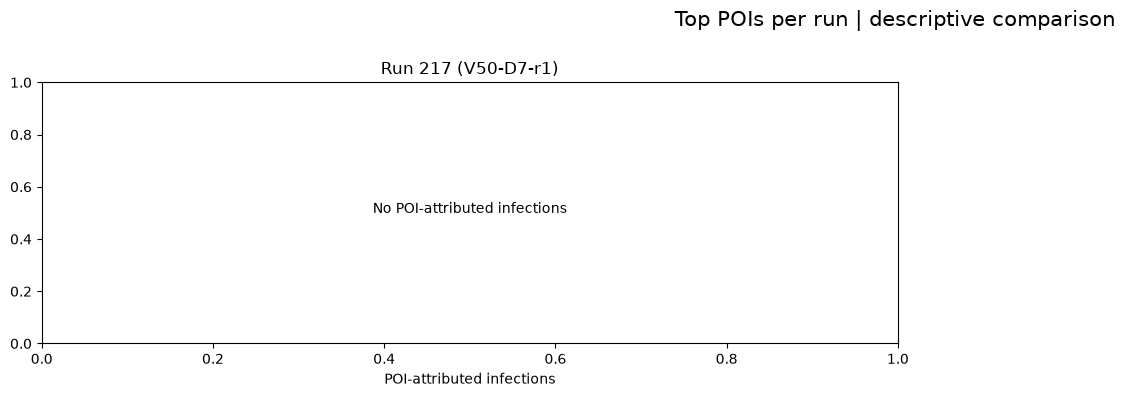

In [23]:
# Figure 1: each run's Top N POIs; all panels share x-axis limits.
nrows = int(np.ceil(len(run_order) / 2))
fig, axes = plt.subplots(nrows, 2, figsize=(18, 4 * nrows), squeeze=False)
xmax = max(1, float(poi_matrix.max().max()) * 1.1)
for ax, rid in zip(axes.flat, run_order):
    s = poi_matrix[rid]
    s = s[s > 0].sort_values(ascending=False, kind="stable").head(TOP_N).sort_values()
    if s.empty:
        ax.text(.5, .5, "No POI-attributed infections", ha="center", transform=ax.transAxes)
    else:
        ax.barh(range(len(s)), s.values, color="#297f9f")
        ax.set_yticks(range(len(s)), poi_names(s.index), fontsize=8)
    ax.set(xlim=(0, xmax), title=f"Run {rid} ({loaded_runs[rid]['label']})", xlabel="POI-attributed infections")
for ax in list(axes.flat)[len(run_order):]:
    ax.set_visible(False)
fig.suptitle("Top POIs per run | descriptive comparison", fontsize=15)
fig.tight_layout(rect=(0, 0, 1, .98))
save_poi_figure(fig, "01_top_pois")

## Scenario medians and differences from baseline

Need B0 plus at least one other scenario; difference panel skipped.


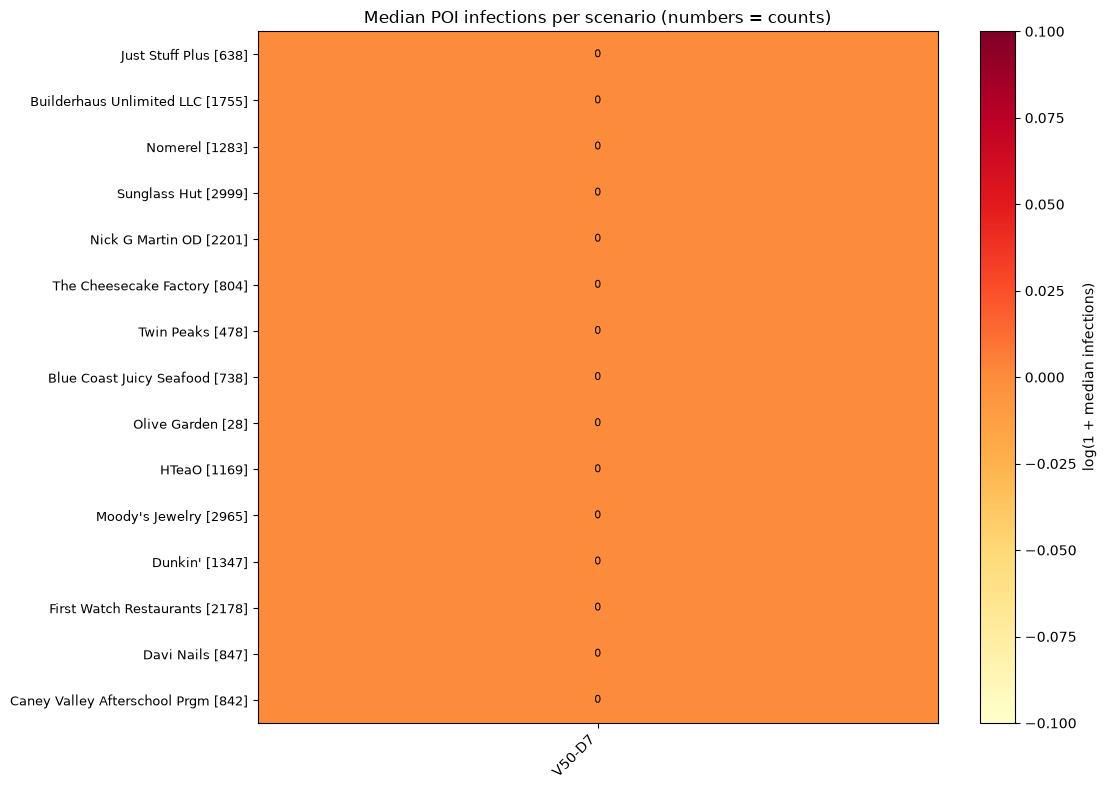

In [24]:
# Figure 2: median POI infections per scenario (left) and median difference vs baseline (right).
display_keys = scenario_poi.max(axis=1).sort_values(ascending=False, kind="stable").head(TOP_N).index
fig, axes = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw=dict(width_ratios=[1, 1]))
M = scenario_poi.loc[display_keys]
im = axes[0].imshow(np.log1p(M), aspect="auto", cmap="YlOrRd")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        axes[0].text(j, i, f"{M.iloc[i, j]:.0f}", ha="center", va="center", fontsize=8)
axes[0].set_xticks(range(M.shape[1]), M.columns, rotation=45, ha="right")
axes[0].set_yticks(range(len(display_keys)), poi_names(display_keys, 40), fontsize=9)
axes[0].set_title("Median POI infections per scenario (numbers = counts)")
fig.colorbar(im, ax=axes[0], label="log(1 + median infections)")

if BASELINE_SCENARIO in scenario_poi and len(SCENARIO_ORDER) > 1:
    others = [s for s in SCENARIO_ORDER if s != BASELINE_SCENARIO]
    diff = scenario_poi[others].sub(scenario_poi[BASELINE_SCENARIO], axis=0)   # negative = fewer than baseline
    diff.to_csv(POI_OUTPUT_DIR / "poi_median_diff_vs_baseline.csv", encoding="utf-8-sig")
    D = diff.loc[display_keys]
    lim = max(1, float(np.abs(D.to_numpy()).max()))
    im2 = axes[1].imshow(D, aspect="auto", cmap="RdBu_r", norm=TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim))
    for i in range(D.shape[0]):
        for j in range(D.shape[1]):
            axes[1].text(j, i, f"{D.iloc[i, j]:+.0f}", ha="center", va="center", fontsize=8)
    axes[1].set_xticks(range(D.shape[1]), D.columns, rotation=45, ha="right")
    axes[1].set_yticks(range(len(display_keys)), [""] * len(display_keys))
    axes[1].set_title(f"Scenario median − {BASELINE_SCENARIO} median | blue: fewer, red: more")
    fig.colorbar(im2, ax=axes[1], label="Difference in median infections")
    if scenario_poi[BASELINE_SCENARIO].sum() == 0:
        print(f"{BASELINE_SCENARIO} median has zero POI infections: reductions are impossible to show. "
              "If the baseline rarely spreads, compare against the earliest-start scenario instead.")
else:
    axes[1].set_visible(False)
    print(f"Need {BASELINE_SCENARIO} plus at least one other scenario; difference panel skipped.")
fig.tight_layout(); save_poi_figure(fig, "02_scenario_medians")

## Hotspot rank shifts and overlap

Rank-shift plot needs two loaded runs.


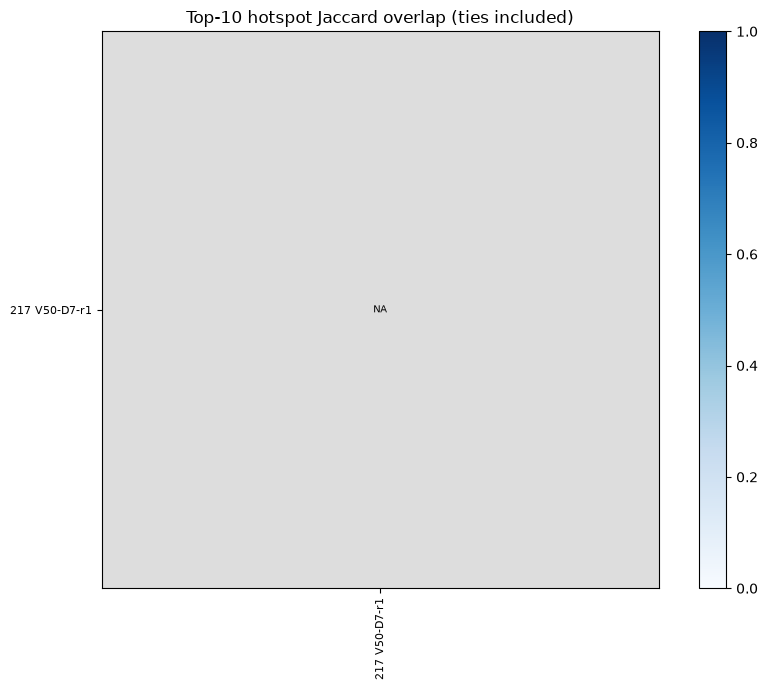

In [25]:
# Figure 3: rank shifts between two runs. Default: the two runs with the most POI infections.
RANK_RUN_IDS = None    # or e.g. (201, 215)
if RANK_RUN_IDS is None:
    RANK_RUN_IDS = tuple(poi_matrix.sum().sort_values(ascending=False).index[:2])
if len(RANK_RUN_IDS) == 2 and all(r in poi_matrix for r in RANK_RUN_IDS):
    left_id, right_id = RANK_RUN_IDS
    left, right = poi_matrix[left_id], poi_matrix[right_id]
    lr = left.where(left > 0).rank(method="min", ascending=False)
    rr = right.where(right > 0).rank(method="min", ascending=False)
    keys = poi_matrix[[left_id, right_id]].max(axis=1).sort_values(ascending=False, kind="stable")
    keys = keys[keys > 0].head(TOP_N).index
    fig, ax = plt.subplots(figsize=(16, 9))
    if left.sum() == 0 or right.sum() == 0:
        ax.text(.5, .5, "One run has no POI infections; rank shift is not meaningful.", ha="center", transform=ax.transAxes)
        ax.axis("off")
    else:
        maxrank = max(lr.loc[keys].max(), rr.loc[keys].max())
        unranked = maxrank + 5
        label_positions = []
        for ranks in (lr, rr):
            ordered = sorted(keys, key=lambda k: (ranks[k] if pd.notna(ranks[k]) else unranked, k))
            label_positions.append(dict(zip(ordered, np.linspace(1, unranked - 1, len(ordered)))))
        for n_, k in enumerate(keys):
            a, b = lr[k], rr[k]
            y1, y2 = (a if pd.notna(a) else unranked), (b if pd.notna(b) else unranked)
            ax.plot([0, 1], [y1, y2], "o-", color=plt.get_cmap("tab20")(n_ % 20), alpha=.8)
            name = str(poi_info.loc[k, "label"])
            lpos, rpos = label_positions[0][k], label_positions[1][k]
            ax.plot([-.13, 0], [lpos, y1], color="gray", lw=.5, alpha=.5)
            ax.plot([1, 1.13], [y2, rpos], color="gray", lw=.5, alpha=.5)
            lrank = f"#{a:.0f}" if pd.notna(a) else "unranked"
            rrank = f"#{b:.0f}" if pd.notna(b) else "unranked"
            ax.text(-.15, lpos, f"{name[:32]} ({left[k]:.0f}; {lrank})", ha="right", va="center", fontsize=8)
            ax.text(1.15, rpos, f"{name[:32]} ({right[k]:.0f}; {rrank})", ha="left", va="center", fontsize=8)
        ax.set(xlim=(-1.1, 2.1), ylim=(unranked + 2, 0), ylabel="Rank among all positive-infection POIs")
        ax.set_xticks([0, 1], [f"Run {left_id}", f"Run {right_id}"])
        ax.set_title("Hotspot rank shifts | labels show infection counts; ties share ranks")
    fig.tight_layout(); save_poi_figure(fig, "03_rank_shifts")
    pd.DataFrame({"label": poi_info["label"], f"rank_{left_id}": lr, f"rank_{right_id}": rr,
                  f"count_{left_id}": left, f"count_{right_id}": right}).to_csv(
        POI_OUTPUT_DIR / "rank_changes.csv", encoding="utf-8-sig")
else:
    print("Rank-shift plot needs two loaded runs.")

# Figure 4: Top-10 hotspot Jaccard overlap between runs (ties included; NA if a run has no POI infections).
top_sets = {}
for rid in run_order:
    s = poi_matrix[rid]; positive = s[s > 0]
    cutoff = positive.nlargest(10).min() if not positive.empty else np.nan
    top_sets[rid] = set(positive[positive >= cutoff].index)
overlap = pd.DataFrame(np.nan, index=run_order, columns=run_order)
for a in run_order:
    for b in run_order:
        if top_sets[a] and top_sets[b]:
            overlap.loc[a, b] = len(top_sets[a] & top_sets[b]) / len(top_sets[a] | top_sets[b])
size = max(7, .55 * len(run_order))
fig, ax = plt.subplots(figsize=(size + 2, size))
cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("#dddddd")
im = ax.imshow(overlap.astype(float), cmap=cmap, vmin=0, vmax=1)
for i in range(len(run_order)):
    for j in range(len(run_order)):
        v = overlap.iloc[i, j]
        ax.text(j, i, "NA" if pd.isna(v) else f"{v:.2f}", ha="center", va="center", fontsize=7)
ticks = [f"{rid} {loaded_runs[rid]['label']}" for rid in run_order]
ax.set_xticks(range(len(run_order)), ticks, rotation=90, fontsize=8)
ax.set_yticks(range(len(run_order)), ticks, fontsize=8)
ax.set_title("Top-10 hotspot Jaccard overlap (ties included)")
fig.colorbar(im, ax=ax); fig.tight_layout(); save_poi_figure(fig, "04_hotspot_overlap")
overlap.to_csv(POI_OUTPUT_DIR / "hotspot_overlap.csv")

## Transmission composition by Home/POI and category

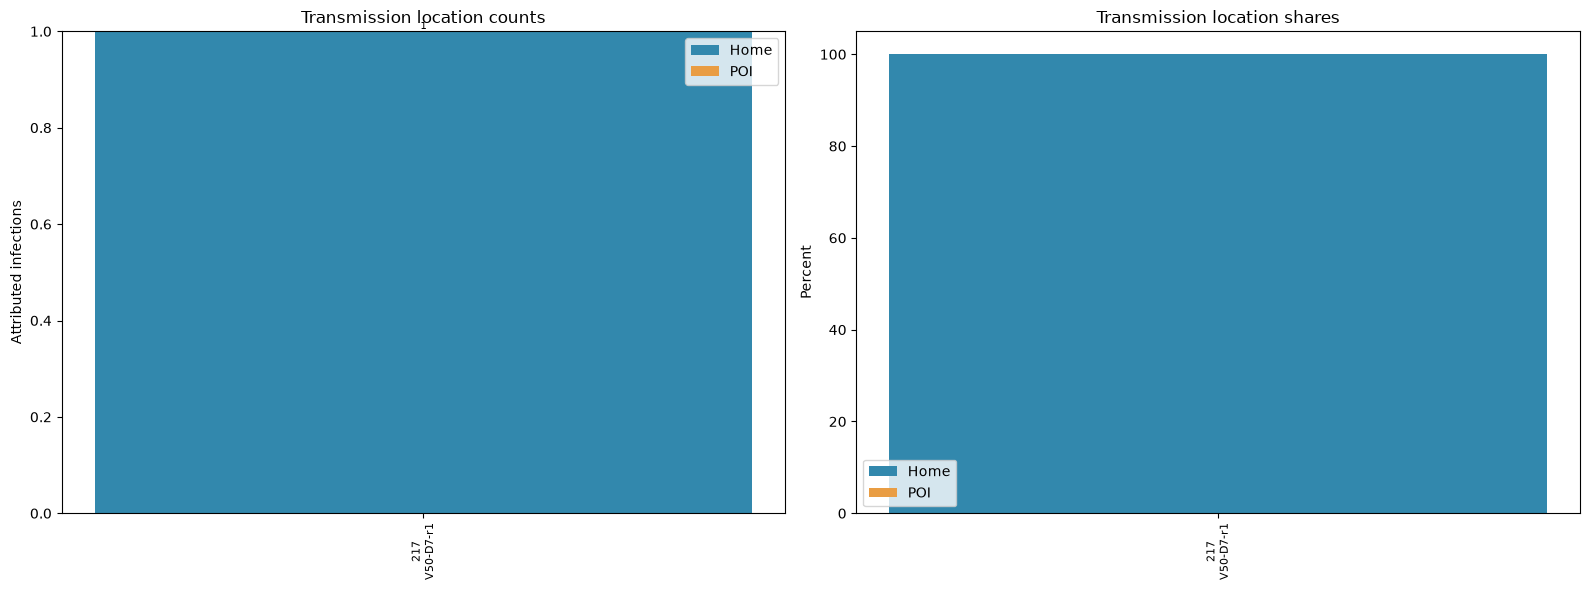

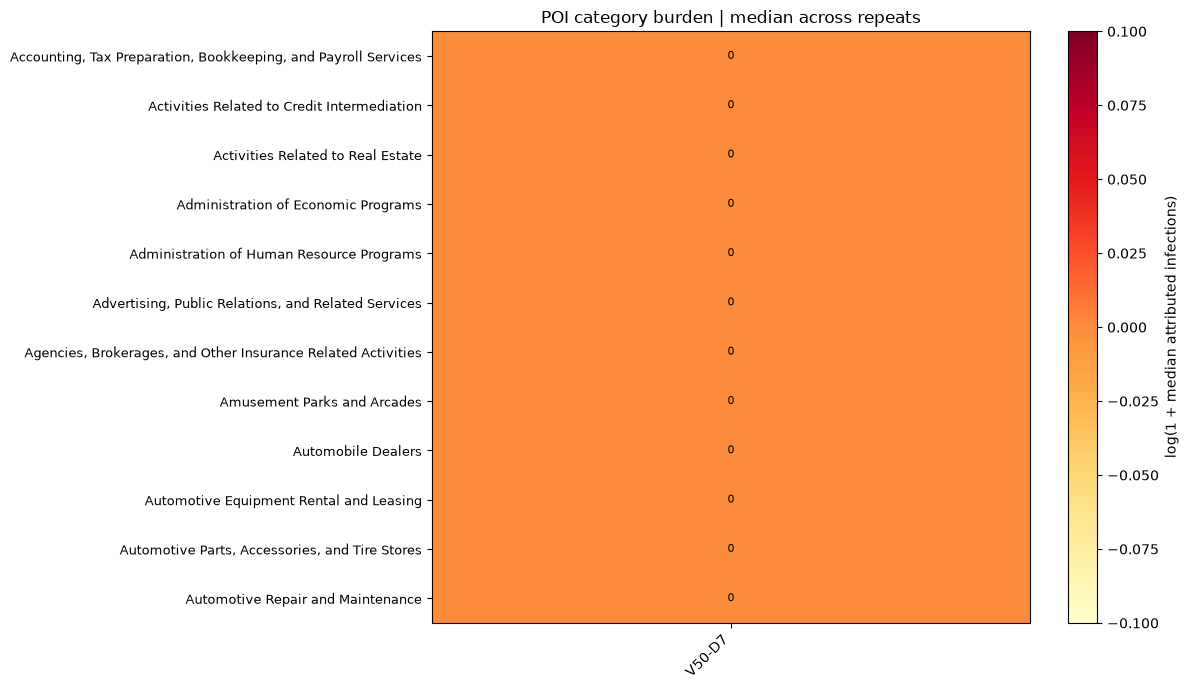

Figures and data saved to: /Users/winniechan/delineo/delineo_exports/poi_comparison


In [26]:
# Figure 5: counts and shares per run, grouped by scenario.
fig, axes = plt.subplots(1, 2, figsize=(max(16, .9 * len(run_order) * 2), 6))
x = np.arange(len(run_order)); totals = transmission_summary["total"]
xt = [f"{rid}\n{loaded_runs[rid]['label']}" for rid in run_order]
for ax, percent in zip(axes, [False, True]):
    home, poi = transmission_summary["home"], transmission_summary["poi"]
    if percent:
        home, poi = 100 * home / totals.replace(0, np.nan), 100 * poi / totals.replace(0, np.nan)
    ax.bar(x, home, label="Home", color="#3288ad")
    ax.bar(x, poi, bottom=home, label="POI", color="#e99d43")
    ax.set_xticks(x, xt, rotation=90, fontsize=8)
    ax.set(ylabel="Percent" if percent else "Attributed infections",
           title="Transmission location shares" if percent else "Transmission location counts")
    if percent:
        ax.set_ylim(0, 105)
    else:
        for i, total in enumerate(totals):
            ax.text(i, total, f"{total:.0f}", ha="center", va="bottom", fontsize=7)
    ax.legend()
fig.tight_layout(); save_poi_figure(fig, "05_home_poi")

# Figure 6: category burden by scenario (median across repeats); log1p only for colors, CSV keeps raw counts.
category_by_run = poi_counts.groupby(["top_category", "run_id"])["infections"].sum().unstack("run_id").reindex(columns=run_order)
category_by_run.to_csv(POI_OUTPUT_DIR / "category_counts_by_run.csv", encoding="utf-8-sig")
category_matrix = category_by_run.T.groupby(scenario_of).median().T.reindex(columns=SCENARIO_ORDER)
category_matrix.to_csv(POI_OUTPUT_DIR / "category_median_by_scenario.csv", encoding="utf-8-sig")
top_categories = category_matrix.max(axis=1).nlargest(12).index
fig, ax = plt.subplots(figsize=(12, 7))
C = category_matrix.loc[top_categories]
im = ax.imshow(np.log1p(C), aspect="auto", cmap="YlOrRd")
for i in range(C.shape[0]):
    for j in range(C.shape[1]):
        ax.text(j, i, f"{C.iloc[i, j]:.0f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(SCENARIO_ORDER)), SCENARIO_ORDER, rotation=45, ha="right")
ax.set_yticks(range(len(top_categories)), top_categories, fontsize=9)
ax.set_title("POI category burden | median across repeats")
fig.colorbar(im, ax=ax, label="log(1 + median attributed infections)")
fig.tight_layout(); save_poi_figure(fig, "06_category_patterns")
print("Figures and data saved to:", POI_OUTPUT_DIR.resolve())

# School hotspots: St John Catholic School and Avant Public School

**Part A** uses the cached incidence totals (no extra downloads) for every run.
**Part B** downloads hourly snapshots for the two schools. With a 720 h window this is 720 requests per run, so it is limited to `SCHOOL_HOURLY_RUNS` (default: the first repeat of each scenario), runs in parallel, and is cached per run so it can resume after an interruption.

School place indices: {'St John Catholic School': 2649, 'Avant Public School': 1419}


median                                         min  \
school   Avant Public School St John Catholic School Avant Public School   
scenario                                                                   
V50-D7                   0.0                     0.0                 0.0   

                                                 max                          
school   St John Catholic School Avant Public School St John Catholic School  
scenario                                                                      
V50-D7                       0.0                 0.0                     0.0

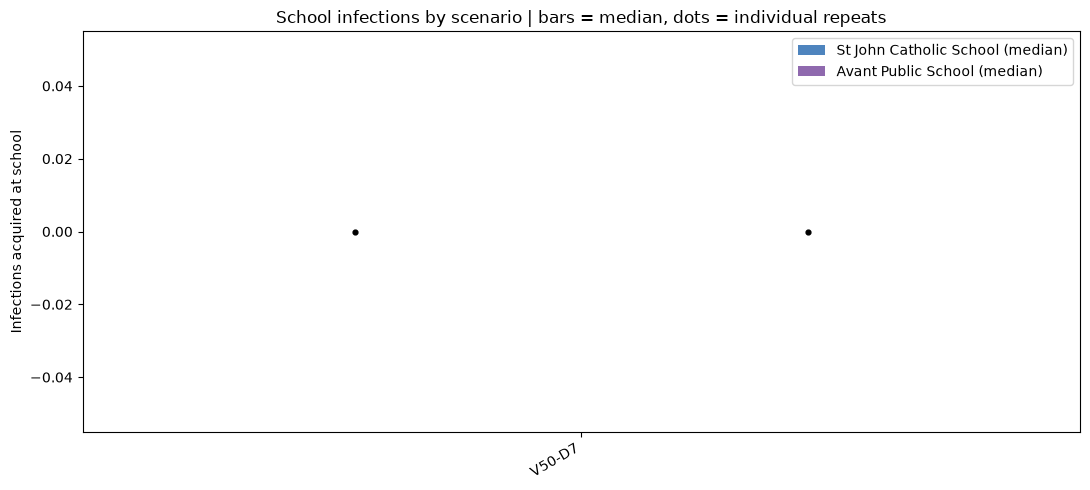

In [27]:
SCHOOL_DIR = EXPORT_DIR / "schools"; SCHOOL_DIR.mkdir(parents=True, exist_ok=True)
SCHOOL_NAMES = ["St John Catholic School", "Avant Public School"]

any_places = pd.DataFrame(next(iter(loaded_runs.values()))["map_json"]["data"]["papdata"]["places"])
school_idx = {}
for name in SCHOOL_NAMES:
    hits = any_places[any_places["label"].astype(str).str.contains(name, case=False, regex=False)]
    if len(hits) != 1:
        raise ValueError(f"Expected exactly one POI named {name!r}, found {len(hits)}: {hits['label'].tolist()}")
    school_idx[name] = int(hits.index[0])
print("School place indices:", school_idx)

# Part A: school infections, share of all infections, and rank among POIs — every run
rows = []
for rid in run_order:
    s = poi_matrix[rid]; ranks = s.where(s > 0).rank(method="min", ascending=False)
    total = transmission_summary.loc[rid, "total"]
    for name, idx in school_idx.items():
        key = any_places.loc[idx, "placekey"]
        rows.append(dict(run_id=rid, scenario=scenario_of[rid], school=name, infections=s[key],
                         rank=ranks[key], share_of_all_pct=100 * s[key] / total if total else np.nan))
school_totals = pd.DataFrame(rows)
school_totals.to_csv(SCHOOL_DIR / "school_totals_by_run.csv", index=False, encoding="utf-8-sig")
school_by_scenario = (school_totals.pivot_table(index="scenario", columns="school", values="infections",
                                                aggfunc=["median", "min", "max"]).reindex(SCENARIO_ORDER))
display(school_by_scenario)
school_by_scenario.to_csv(SCHOOL_DIR / "school_totals_by_scenario.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(11, 5))
w = .38
for k, name in enumerate(SCHOOL_NAMES):
    d = school_totals[school_totals["school"] == name]
    med = d.groupby("scenario")["infections"].median().reindex(SCENARIO_ORDER)
    xs = np.arange(len(SCENARIO_ORDER)) + (k - .5) * w
    ax.bar(xs, med.values, w, label=f"{name} (median)", color=["#2f6fb3", "#7b4fa0"][k], alpha=.85)
    for j, sc in enumerate(SCENARIO_ORDER):
        pts = d.loc[d["scenario"] == sc, "infections"]
        ax.scatter(np.full(len(pts), xs[j]), pts, color="k", s=12, zorder=3)
ax.set_xticks(range(len(SCENARIO_ORDER)), SCENARIO_ORDER, rotation=30, ha="right")
ax.set_ylabel("Infections acquired at school"); ax.legend()
ax.set_title("School infections by scenario | bars = median, dots = individual repeats")
fig.tight_layout(); fig.savefig(SCHOOL_DIR / "07_school_totals.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

run 217: hourly school data ready (0s)


,run_id,school,hourly_sum,infections,matches
0,217,Avant Public School,0,0.0,True
1,217,St John Catholic School,0,0.0,True


,run_id,scenario,school,first_infected_present_hour,first_local_infection_hour,total_local,person_hours
0,217,V50-D7,Avant Public School,NaN,NaN,0,63838
1,217,V50-D7,St John Catholic School,NaN,NaN,0,59952


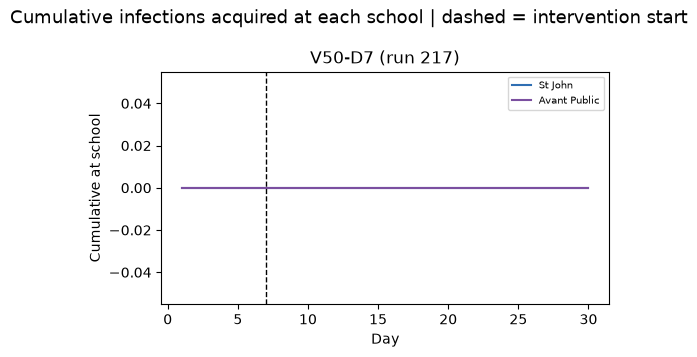

In [28]:
# Part B: hourly series for the two schools
RUN_SCHOOL_HOURLY = True
SCHOOL_HOURLY_RUNS = None   # None = first repeat of each scenario; or a list of run IDs
MAX_WORKERS = 8

if SCHOOL_HOURLY_RUNS is None:
    SCHOOL_HOURLY_RUNS = [next(r for r in run_order if scenario_of[r] == sc) for sc in SCENARIO_ORDER]

def school_rows_at(rid, api_time):
    snap = get_snapshot(rid, api_time)
    frame = snap["simdata"][str(snap["time"])]
    p = np.asarray(frame["p"]).reshape(-1, 2); pinc = np.asarray(frame["pinc"])
    return [dict(run_id=rid, api_time=snap["time"], school=name,
                 attendance=int(p[i, 0]), infected_present=int(p[i, 1]), new_local=int(pinc[i]))
            for name, i in school_idx.items()]

def hourly_for_run(rid):
    path = SCHOOL_DIR / f"hourly_run_{rid}.csv"
    if path.exists() and not REFRESH_CACHE:
        return pd.read_csv(path)
    ts = loaded_runs[rid]["map_json"]["data"]["timesteps"]
    out = []
    with ThreadPoolExecutor(MAX_WORKERS) as ex:
        futures = [ex.submit(school_rows_at, rid, t) for t in ts]
        for f in as_completed(futures):
            out.extend(f.result())
    df = pd.DataFrame(out).sort_values(["school", "api_time"]).reset_index(drop=True)
    df.to_csv(path, index=False)
    return df

if RUN_SCHOOL_HOURLY:
    parts = []
    for rid in SCHOOL_HOURLY_RUNS:
        t0 = _time.time(); parts.append(hourly_for_run(rid))
        print(f"run {rid}: hourly school data ready ({_time.time() - t0:.0f}s)")
    school_hourly = pd.concat(parts, ignore_index=True)
    school_hourly["hour"] = school_hourly["api_time"] / API_MIN_PER_HOUR
    school_hourly["day"] = np.ceil(school_hourly["hour"] / 24).astype(int)
    school_hourly["scenario"] = school_hourly["run_id"].map(scenario_of)

    # Check: hourly local incidence must add up to the cached totals from Part A.
    chk = school_hourly.groupby(["run_id", "school"])["new_local"].sum().rename("hourly_sum").reset_index()
    chk = chk.merge(school_totals[["run_id", "school", "infections"]], on=["run_id", "school"])
    chk["matches"] = chk["hourly_sum"] == chk["infections"]
    display(chk)
    if not chk["matches"].all():
        warnings.warn("Hourly local incidence does not sum to incidence totals for some runs — inspect before using.")

    timing = (school_hourly
              .assign(_ip=school_hourly["hour"].where(school_hourly["infected_present"] > 0),
                      _li=school_hourly["hour"].where(school_hourly["new_local"] > 0))
              .groupby(["run_id", "scenario", "school"])
              .agg(first_infected_present_hour=("_ip", "min"), first_local_infection_hour=("_li", "min"),
                   total_local=("new_local", "sum"), person_hours=("attendance", "sum"))
              .reset_index())
    display(timing)
    timing.to_csv(SCHOOL_DIR / "school_timing.csv", index=False, encoding="utf-8-sig")

    daily = school_hourly.groupby(["run_id", "scenario", "school", "day"])["new_local"].sum().reset_index()
    daily["cumulative"] = daily.groupby(["run_id", "school"])["new_local"].cumsum()
    daily.to_csv(SCHOOL_DIR / "school_daily.csv", index=False, encoding="utf-8-sig")

    # Figure 8: cumulative school infections per scenario, shared y scale, intervention start marked
    runs_b = SCHOOL_HOURLY_RUNS; ncols = min(3, len(runs_b)); nrows = int(np.ceil(len(runs_b) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 3.6 * nrows), sharex=True, sharey=True, squeeze=False)
    for ax, rid in zip(axes.flat, runs_b):
        for name, color in zip(SCHOOL_NAMES, ["#2f6fb3", "#7b4fa0"]):
            d = daily[(daily["run_id"] == rid) & (daily["school"] == name)]
            ax.plot(d["day"], d["cumulative"], color=color, label=name.split()[0] + " " + name.split()[1])
        sh = start_hour_of.get(scenario_of[rid])
        if sh is not None:
            ax.axvline(sh / 24, ls="--", color="k", lw=1)
        ax.set_title(f"{scenario_of[rid]} (run {rid})"); ax.set_xlabel("Day"); ax.set_ylabel("Cumulative at school")
        ax.legend(fontsize=7)
    for ax in list(axes.flat)[len(runs_b):]:
        ax.set_visible(False)
    fig.suptitle("Cumulative infections acquired at each school | dashed = intervention start", fontsize=13)
    fig.tight_layout(); fig.savefig(SCHOOL_DIR / "08_school_cumulative.png", dpi=180, bbox_inches="tight"); plt.show(); plt.close(fig)

## Reading the results — checklist

- **Audit first.** Only runs that passed the settings audit are interpretable as intervention scenarios.
- **The window is capped at 30 days.** If spreading runs still peak in the last 5% of the window, report totals as infections by day 30, not final outbreak size.
- **Use repeats.** Compare scenario medians and ranges, and report how many repeats spread at all (`n_spread`). One run is not a result.
- **Timing question:** does a later start (day 0.5 → 21) give a larger outbreak and more school infections than an early start, and is there a start day after which vaccination no longer changes the outcome?
- **Locations, not chains.** Home/POI and school counts say where infections happened, not who infected whom.